# TrustVision - Membre C : SimCLR (S1) & EWC (S4)

Ce notebook reproduit les deux étapes du Membre C du cahier des charges :

* **S1 - Contrastive Learning (SimCLR)** : pré-entraînement auto-supervisé sur les images sans étiquettes, puis sondes linéaires gelées à **1 %, 5 %, 10 % et 100 %** des étiquettes. Comparaison avec un **CNN entraîné from scratch** sur les mêmes budgets et avec la **sonde CLIP** (S0).
* **S4 - Continual Learning (EWC)** : encodeur SimCLR pré-entraîné **uniquement sur les 3 classes initiales** (aucune fuite vers les classes 3-5), scénario **single-head 3 → 6 classes sans identifiant de tâche**, comparaison **EWC vs fine-tuning naïf vs replay**, balayage de **lambda**, calibration et robustesse FGSM.

Toutes les métriques proviennent de `src.eval.evaluate_all` (même contrat que S0/S2/S3). Aucune valeur n'est simulée : les JSON sont écrits à partir des exécutions réelles.

> **État actuel** : S1 a déjà été exécuté (résultats réels dans `results/s1_simclr.json`). Ce notebook Colab sert à terminer **S4 sur GPU**, puis à mettre à jour la matrice d'effets croisés avec les deux étapes.

## 0. Préparation Colab

1. Téléverser `TrustVision_colab.zip` dans `/content` (icône dossier à gauche) ou dans `Mon Drive/TrustVision_colab.zip`.
2. Exécuter les cellules ci-dessous dans l'ordre.
3. **Ne pas** installer `requirements.txt` : il épingle `torch==2.15.0` et remplacerait le build CUDA préinstallé de Colab. On installe uniquement les paquets manquants.

In [1]:
# 0.1 - Monter Google Drive (recommandé pour sauvegarder les résultats)
USE_DRIVE = True

try:
    from google.colab import drive

    drive.mount("/content/drive")
    DRIVE_OK = True
except Exception as exc:  # hors Colab ou refus d'autorisation
    DRIVE_OK = False
    print("Drive non monté :", exc)

Drive non monté : No module named 'google.colab'


In [2]:
# 0.2 - Extraire le projet et se placer a la racine du depot
import os
import sys
import zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
PROJECT_DIR = Path('/content/TrustVision')
FRESH_EXTRACT = False

if IN_COLAB:
    if FRESH_EXTRACT and PROJECT_DIR.exists():
        import shutil
        shutil.rmtree(PROJECT_DIR)
    if not PROJECT_DIR.exists():
        candidates = [
            Path('/content/drive/MyDrive/TrustVision_colab.zip'),
            Path('/content/TrustVision_colab.zip'),
        ]
        zip_path = next((p for p in candidates if p.exists()), None)
        if zip_path is None:
            from google.colab import files
            uploaded = files.upload()
            zip_path = Path(next(iter(uploaded)))
        print('Extraction de', zip_path)
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall('/content')
    os.chdir(PROJECT_DIR)
    sys.path.insert(0, str(PROJECT_DIR))

print('Repertoire courant :', Path.cwd())


Répertoire courant : D:\work\cycle\S5\IA avance\Projet


In [3]:
# 0.3 - Vérifier PyTorch/CUDA et installer seulement les paquets manquants
import importlib.util
import subprocess
import sys

import torch

print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("⚠️ Aucun GPU : Exécution > Modifier le type d'exécution > T4 GPU")

missing = []
for module, package in (
    ("sklearn", "scikit-learn"),
    ("matplotlib", "matplotlib"),
    ("requests", "requests"),
    ("pandas", "pandas"),
    ("pytest", "pytest"),
):
    if importlib.util.find_spec(module) is None:
        missing.append(package)

if missing:
    print("Installation :", missing)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *missing],
        check=True,
    )
else:
    print("Toutes les dépendances sont déjà présentes.")

PyTorch : 2.15.0+cpu
CUDA disponible : False
⚠️ Aucun GPU : Exécution > Modifier le type d'exécution > T4 GPU
Toutes les dépendances sont déjà présentes.


In [4]:
# 0.4 - Tests Membre C (rapides, sans entraînement long)
!python -m pytest tests/test_exp_c.py -q

Python was not found; run without arguments to install from the Microsoft Store, or disable this shortcut from Settings > Apps > Advanced app settings > App execution aliases.


## 1. Imports

In [5]:
from pathlib import Path
import json

import pandas as pd
import torch
from IPython.display import Image, display

from src.run_member_c import (
    run_s1_simclr,
    run_s4_ewc,
    update_cross_effects_table,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
print("Device :", DEVICE)

Device : cpu


## 2. S1 - SimCLR et efficacité des étiquettes

Le backbone partagé `TrustVisionCNN` est pré-entraîné avec la perte **NT-Xent** sur deux vues augmentées (recadrage aléatoire, flips, rotation, jitter photométrique, flou gaussien). Le projecteur MLP est jeté après pré-entraînement ; seule la représentation 256-d est conservée.

Les sondes sont des régressions logistiques standardisées ajustées sur les features gelées. Le modèle principal S1 est le meilleur des deux candidats à 100 % d'étiquettes (sonde SimCLR ou CNN from scratch).

**Sur Colab, S1 n'est pas ré-exécuté par défaut** : les résultats réels du run local sont chargés depuis `results/s1_simclr.json`. Passer `RUN_S1 = True` pour le refaire sur GPU (attention : les nombres peuvent varier légèrement et le JSON sera écrasé).

In [6]:
RUN_S1 = False

if RUN_S1:
    s1 = run_s1_simclr(
        seed=SEED,
        simclr_epochs=20,
        supervised_epochs=15,
        batch_size=64,
        fractions=(0.01, 0.05, 0.10, 1.0),
        device=DEVICE,
        force_retrain=True,
    )
else:
    s1_path = Path("results/s1_simclr.json")
    s1 = json.loads(s1_path.read_text(encoding="utf-8"))
    print(f"S1 chargé depuis {s1_path} (run réel déjà terminé).")

S1 chargé depuis results\s1_simclr.json (run réel déjà terminé).


In [7]:
rows = []
for key in ("1pct", "5pct", "10pct", "100pct"):
    sim = s1["simclr"]["label_fractions"][key]
    row = {
        "Budget": key.replace("pct", " %"),
        "SimCLR acc": sim["acc"],
        "SimCLR ECE cal.": sim.get("calibrated", {}).get("ece"),
        "SimCLR rob.": sim["rob_acc_003"],
    }
    scratch = s1["supervised_from_scratch"]["label_fractions"].get(key)
    if scratch:
        row["Scratch acc"] = scratch["acc"]
        row["Scratch ECE cal."] = scratch.get("calibrated", {}).get("ece")
    rows.append(row)

display(pd.DataFrame(rows).set_index("Budget").round(4))
print("Modèle principal S1 :", s1["main_model"]["source"])
print("Référence CLIP :", s1["clip_reference"])

,SimCLR acc,SimCLR ECE cal.,SimCLR rob.,Scratch acc,Scratch ECE cal.
Budget,,,,,
1 %,0.7306,0.0608,0.2444,0.2472,0.1383
5 %,0.8833,0.0484,0.2833,0.3111,0.1755
10 %,0.9056,0.0390,0.2361,0.8750,0.0438
100 %,0.9722,0.0087,0.1500,0.9778,0.0122


Modèle principal S1 : Supervised CNN from scratch (100% labels)
Référence CLIP : {'acc': 0.9944, 'ece': 0.0056, 'rob_acc_003': 0.2111}


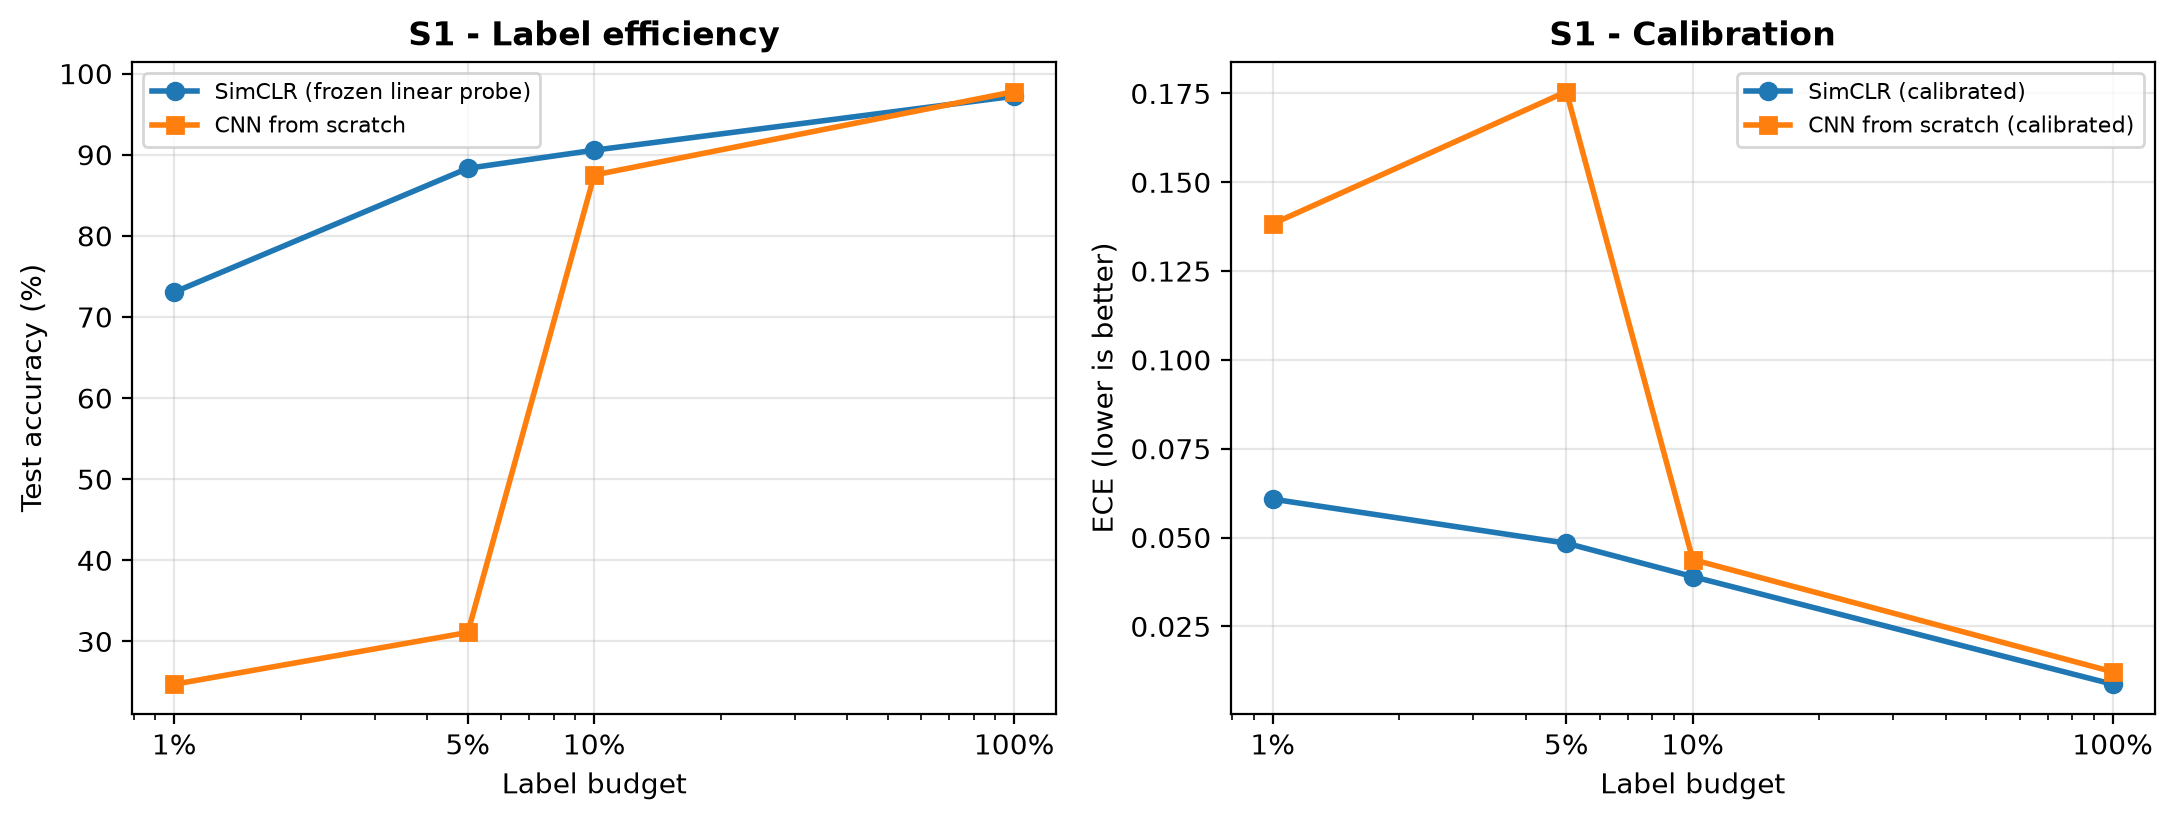

In [8]:
figure = Path("results/figures/s1_simclr_label_efficiency.png")
if figure.exists():
    display(Image(filename=str(figure)))
else:
    print("Figure absente : exécuter la cellule S1.")

## 3. S4 - Apprentissage continu avec EWC

Protocole :

1. Un encodeur SimCLR **distinct** est pré-entraîné sur les images des **3 classes initiales uniquement** (`crazing`, `inclusion`, `patches`). Il est ré-entraîné ici sur GPU (le zip ne contient pas le backbone 3 classes du run local interrompu).
2. La tête 3 classes est entraînée sur la tâche 1.
3. La matrice de Fisher diagonale est estimée sur les données de la tâche 1.
4. La tête est étendue de 3 à 6 sorties ; les nouvelles lignes sont initialisées sans contrainte EWC.
5. Trois familles sont comparées : **naïve**, **EWC** (balayage de lambda) et **replay** (buffer de 120 images de la tâche 1, **40 par ancienne classe**).
6. Une variante **EWC + replay** combine le meilleur lambda EWC avec le buffer stratifié.

La Fisher diagonale est **normalisée par tenseur** (moyenne = 1) : sur un CNN saturé, les gradients des couches profondes sont plusieurs ordres de grandeur sous ceux de `block1`, et un lambda global unique ne les contraint pas. Cette normalisation garde la formule EWC et rend lambda comparable entre couches.

L'évaluation se fait sur les 6 classes, sans identifiant de tâche. Le **forgetting** est la perte d'exactitude sur les anciennes classes entre la fin de la tâche 1 et la fin de la tâche 2.

Durée indicative sur T4 : ~12-20 min (encodeur SimCLR inclus, 7 stratégies). Le JSON `results/s4_ewc.json` n'est écrit qu'à la fin : ne pas interrompre la cellule.

In [9]:
RUN_S4 = False

if RUN_S4:
    s4 = run_s4_ewc(
        seed=SEED,
        simclr_epochs=20,
        task1_epochs=10,
        task2_epochs=10,
        batch_size=32,
        ewc_lambdas=(0.1, 1.0, 10.0, 100.0),
        replay_size=120,
        fisher_normalization='per_tensor',
        include_ewc_replay=True,
        device=DEVICE,
    )
else:
    s4 = json.loads(Path('results/s4_ewc.json').read_text(encoding='utf-8'))


In [10]:
rows = []
for key, strategy in s4["strategies"].items():
    metrics = strategy["metrics"]
    rows.append({
        "Stratégie": key,
        "Lambda": strategy["ewc_lambda"],
        "Acc globale": metrics["acc"],
        "Acc anciennes": metrics["old_acc"],
        "Acc nouvelles": metrics["new_acc"],
        "Forgetting": metrics.get("forgetting"),
        "ECE": metrics["ece"],
        "ECE cal.": metrics.get("calibrated", {}).get("ece"),
        "T ajusté": metrics.get("calibrated", {}).get("temperature_fitted"),
        "Calibration": metrics.get("calibrated", {}).get("calibration_accepted", True),
        "Rob. FGSM": metrics["rob_acc_003"],
    })

display(pd.DataFrame(rows).set_index("Stratégie").round(4))
print("Meilleur EWC :", s4["best_ewc"]["strategy"], "| checkpoint :", s4["canonical_checkpoint"])

,Lambda,Acc globale,Acc anciennes,Acc nouvelles,Forgetting,ECE,ECE cal.,T ajusté,Calibration,Rob. FGSM
Stratégie,,,,,,,,,,
naive,0.0,0.4972,0.0000,0.9944,1.0000,0.4005,0.1697,4.9279,True,0.0389
replay,0.0,0.9306,0.9333,0.9278,0.0667,0.0495,0.0266,0.6685,True,0.0722
ewc_lambda_0.1,0.1,0.4972,0.0000,0.9944,1.0000,0.3861,0.1830,3.8164,True,0.1417
ewc_lambda_1,1.0,0.5083,0.0222,0.9944,0.9778,0.3438,0.1960,2.8186,True,0.1167
ewc_lambda_10,10.0,0.5556,0.1444,0.9667,0.8556,0.2775,0.1031,2.7164,True,0.0667
ewc_lambda_100,100.0,0.4750,0.0000,0.9500,1.0000,0.3682,0.1134,4.1079,True,0.1917
ewc_replay,10.0,0.8639,0.9278,0.8000,0.0722,0.0765,0.0765,0.0010,False,0.1500


Meilleur EWC : ewc_replay | checkpoint : checkpoints/ewc_seed42.pt


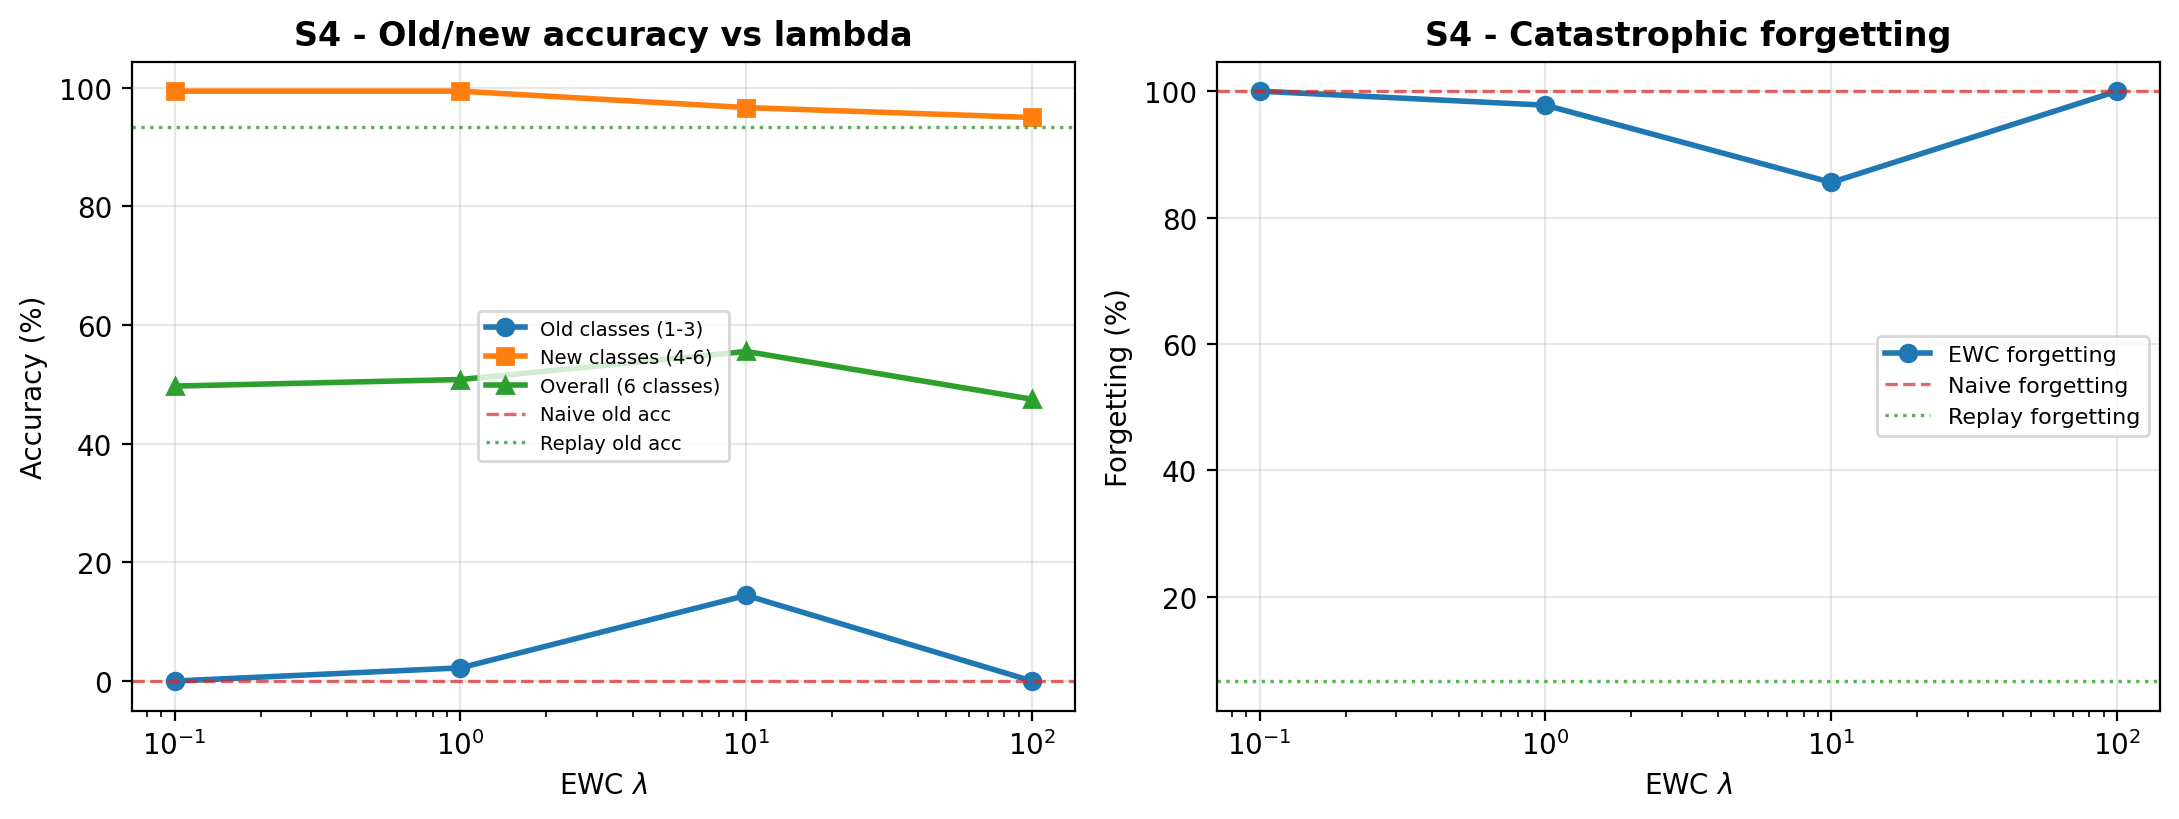

In [11]:
figure = Path("results/figures/s4_ewc_lambda_sweep.png")
if figure.exists():
    display(Image(filename=str(figure)))
else:
    print("Figure absente : exécuter la cellule S4.")

## 4. Matrice d'effets croisés S0-S4

Les lignes S1 et S4 du tableau partagé sont remplacées par les mesures réelles (ECE calibrée pour la comparaison avec S0/S2 ; repli $T=1$ si la calibration n'améliore pas la NLL de calibration).

In [12]:
table = update_cross_effects_table(s1, s4)
display(pd.DataFrame(table["rows"]).set_index("stage").round(4))

[Cross-Effects] Updated S1/S4 rows in results\cross_effects_table.json


,acc,macro_f1,ece,nll,brier,rob_acc_003,xai_sim,intra_xai_stab,forgetting,status,calibration_note
stage,,,,,,,,,,,
S0_CLIP_LinearProbe,0.9944,0.9945,0.0056,0.0159,0.0088,0.2111,NaN,NaN,NaN,COMPLETED,NaN
S1_SimCLR,0.9722,0.9722,0.0087,0.0785,0.0430,0.1500,0.7118,NaN,NaN,COMPLETED,NaN
S2_CNN_Base_Calibrated,0.9806,0.9806,0.0121,0.0566,0.0302,0.2111,0.7663,NaN,NaN,COMPLETED,NaN
S3_CNN_Adversarial_Defense,0.9389,0.9389,0.0379,0.1704,0.0914,0.7611,NaN,0.9090,NaN,COMPLETED,NaN
S4_EWC_Continual,0.8639,0.8633,0.0765,0.4178,0.2210,0.1500,0.7961,0.9831,0.0722,COMPLETED,Fitted T=0.001 rejected: calibration NLL 1.188...


## 5. Mini-TP : inspecter une stratégie S4

Le curseur permet de choisir une stratégie (naïve, replay ou un lambda EWC) et d'afficher ses métriques réelles, sans ré-entraînement. C'est le support du mini-TP demandé par le cahier des charges pour le curseur `lambda`.

In [13]:
import ipywidgets as widgets

options = list(s4["strategies"].keys())

def show_strategy(name):
    metrics = s4["strategies"][name]["metrics"]
    print(json.dumps({
        "strategy": name,
        "lambda": s4["strategies"][name]["ewc_lambda"],
        "acc": metrics["acc"],
        "old_acc": metrics["old_acc"],
        "new_acc": metrics["new_acc"],
        "forgetting": metrics.get("forgetting"),
        "ece": metrics["ece"],
        "temperature": metrics.get("temperature"),
        "temperature_fitted": metrics.get("calibrated", {}).get("temperature_fitted"),
        "calibration_accepted": metrics.get("calibrated", {}).get("calibration_accepted"),
        "ece_calibrated": metrics.get("calibrated", {}).get("ece"),
        "rob_acc_003": metrics["rob_acc_003"],
    }, indent=2))

widgets.interact(show_strategy, name=widgets.Dropdown(options=options, description="Stratégie"));

interactive(children=(Dropdown(description='Stratégie', options=('naive', 'replay', 'ewc_lambda_0.1', 'ewc_lam…

## 6. Sauvegarde des artefacts

Sauvegarde `results/` et `checkpoints/` dans Google Drive (ou téléchargement d'un zip si le Drive n'est pas monté). À exécuter **après** S4.

In [14]:
import datetime
import shutil

stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")

if DRIVE_OK:
    out_dir = Path("/content/drive/MyDrive/TrustVision_results") / f"run_{stamp}"
    for sub in ("results", "checkpoints"):
        shutil.copytree(sub, out_dir / sub, dirs_exist_ok=True)
    print("Artefacts sauvegardés dans :", out_dir)
else:
    archive = shutil.make_archive(f"/content/trustvision_outputs_{stamp}", "zip", ".", "results")
    print("Archive créée :", archive)
    try:
        from google.colab import files

        files.download(archive)
    except Exception as exc:
        print("Téléchargement indisponible :", exc)

Archive créée : D:\content\trustvision_outputs_20261121_1407.zip
Téléchargement indisponible : No module named 'google.colab'
